# Federated Learning on Fashion-MNIST: FedAvg vs FedProx vs FedNova vs HierFAVG vs FedMA

This notebook reproduces (at a reduced, laptop-friendly scale) the experimental
protocol from *"Comparative study of Privacy Preservation Frameworks using
Federated Learning"* (Mogili Pranav, Sreemoyee Biswas, Sourabh Jain, Bhavya
Sahu, IIIT Bhopal), Section III.

**Dataset.** 70,000 28x28 grayscale clothing-item images across 10 classes (60,000 train / 10,000 test), loaded via `torchvision.datasets.FashionMNIST`. The paper (Sec III-B) describes Fashion-MNIST as a 'slightly harder MNIST': its class boundaries are visually closer together, making it more sensitive to the representation drift non-IID partitioning introduces.

**Non-IID partitioning.** Labels are split across simulated clients using a
Dirichlet(&alpha;) distribution over classes (paper Sec. III-A, Fig. 3/5/6).
Small &alpha; (default 0.1) produces the highly skewed regime the paper
studies, where most clients are dominated by one or two classes.

**Algorithms compared** (paper Sec. II-B/C, Table V):

| Algorithm | Idea |
|---|---|
| **FedAvg** | Baseline data-volume-weighted averaging of client updates (McMahan et al., 2017). |
| **FedProx** | Adds a proximal term `(mu/2)*||w - w_global||^2` to each client's local loss to limit client drift (Li et al., 2020). |
| **FedNova** | Normalises each client's cumulative update by its local step count before combining, removing the bias FedAvg introduces when clients take different numbers of local steps (Wang et al., 2020). |
| **HierFAVG** | Inserts an edge tier between clients and the global server: clients report to nearby edge clusters, edges aggregate locally, and only the (far fewer) cluster models cross the WAN to the global server (Liu et al., 2020). |
| **FedMA-lite** | A simplified version of FedMA (Wang/Yurochkin et al., 2020) that Hungarian-matches the first conv layer's output channels across clients (by cosine similarity) before averaging, instead of naive coordinate-wise averaging. *(Simplification: the full FedMA algorithm matches every layer sequentially and re-trains clients between matched layers; we match only the first conv layer and FedAvg the rest -- see the docstring of `fedma_lite_aggregate` in `federated_core.py`.)* |

**Scale note.** Defaults mirror the paper's own reduced-scale reproduction (20 clients, 4 HierFAVG clusters, 25 rounds, ~52K-parameter CNN, Sec III-A) so this runs in a few minutes on a laptop CPU. You can scale `NUM_CLIENTS`, `NUM_ROUNDS`,
`LOCAL_EPOCHS` and the model up towards the paper's full-scale settings
(100 clients / 200 rounds / ResNet-18 for CIFAR-10 on a GPU) in the config
cell below -- the code does not change, only the numbers.

This notebook needs `torch`, `torchvision`, `scipy`, `matplotlib`, `pandas`,
and an internet connection (to download the dataset the first time it runs).
It imports the shared federated-learning framework from `federated_core.py`,
which must sit in the same folder as this notebook.


In [2]:
import sys, os, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, os.path.abspath("."))
import federated_core as fc

fc.set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [3]:
# ---------------------------------------------------------------------------
# Configuration -- start here at reduced scale, then scale up towards the
# paper's full settings (100 clients, 200 rounds, alpha in {0.1, 0.5, 1.0})
# once you've confirmed the pipeline runs end-to-end.
# ---------------------------------------------------------------------------
NUM_CLIENTS   = 20        # paper's reduced-scale companion study uses 20
NUM_ROUNDS    = 25        # paper's reduced-scale companion study uses 25
LOCAL_EPOCHS  = 5         # paper Sec III-A: five local epochs
BATCH_SIZE    = 32        # paper Sec III-A: batch size 32
LR            = 0.01      # paper Sec III-A: initial learning rate 0.01
ALPHA         = 0.1       # Dirichlet concentration: 0.1 = high skew (paper's primary setting)
MU_FEDPROX    = 0.01      # paper Sec III-C: mu=0.01 was the only value in {0.001,0.01,0.1,1.0} that worked well
NUM_CLUSTERS  = 4         # paper's reduced-scale companion study uses 4 HierFAVG edge clusters
SPEED_LOW, SPEED_HIGH = 0.25, 4.0   # paper Sec III-A: 0.25x-4x relative client compute speed
SEED          = 42



In [4]:
import torchvision
import torchvision.transforms as T

transform = T.Compose([T.ToTensor(), T.Normalize((0.2860,), (0.3530,))])
train_dataset = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)
train_labels = np.array(train_dataset.targets)
print(f"Train size: {len(train_dataset)}, Test size: {len(test_dataset)}")


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.73MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.4MB/s]

Train size: 60000, Test size: 10000



/tmp/ipykernel_1244/104892057.py:7: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  train_labels = np.array(train_dataset.targets)


Client sample counts: [261, 494, 4594, 4738, 434, 6377, 461, 932, 6220, 3716, 2246, 7483, 731, 4174, 397, 2942, 6041, 1358, 3444, 2957]


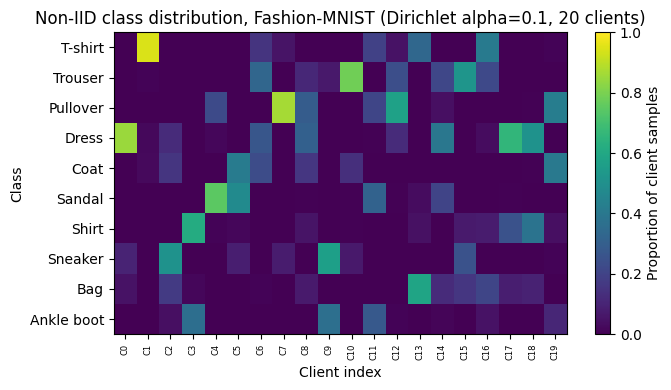

In [5]:
# (dataset already loaded above)

client_indices = fc.dirichlet_partition(
    train_labels, num_clients=NUM_CLIENTS, alpha=ALPHA, num_classes=10, seed=SEED
)
client_sizes = [len(idx) for idx in client_indices]
print("Client sample counts:", client_sizes)

class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
fig, ax = fc.plot_class_distribution(
    train_labels, client_indices, class_names,
    title=f"Non-IID class distribution, Fashion-MNIST (Dirichlet alpha={ALPHA}, {NUM_CLIENTS} clients)"
)
plt.show()


In [6]:
from torch.utils.data import Subset, DataLoader

client_loaders = [
    DataLoader(Subset(train_dataset, idx), batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
    for idx in client_indices
]
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

speed_multipliers = fc.get_client_speed_multipliers(NUM_CLIENTS, SPEED_LOW, SPEED_HIGH, seed=SEED)
cluster_of, clusters = fc.make_edge_clusters(NUM_CLIENTS, NUM_CLUSTERS, seed=SEED)
print("Edge cluster sizes:", [len(c) for c in clusters])


Edge cluster sizes: [5, 3, 6, 6]


## Model

Same compact 2-layer CNN (~52K parameters) as the MNIST notebook, so accuracy differences reflect the dataset, not the architecture.

In [7]:
class SmallCNN(nn.Module):
    """~52K-parameter 2-layer CNN, matching the paper's reduced-scale
    MNIST / Fashion-MNIST companion study (Sec III-A: 'lightweight two-layer
    CNN (~52K parameters)')."""
    def __init__(self, in_channels=1, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(16 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 28x28 -> 14x14
        x = self.pool(F.relu(self.conv2(x)))   # 14x14 -> 7x7
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

def model_fn():
    return SmallCNN(in_channels=1, num_classes=10)

n_params = sum(p.numel() for p in model_fn().parameters())
print(f"Model parameter count: {n_params:,}")


Model parameter count: 52,138


## Run all five algorithms (paper Table VIII layout)

In [8]:
ALGORITHMS = ["FedAvg", "FedProx", "FedNova", "HierFAVG", "FedMA"]
histories = {}

for algo in ALGORITHMS:
    print(f"\n=== Running {algo} ===")
    fc.set_seed(SEED)  # same client sampling / init story for every algorithm
    histories[algo] = fc.run_federated_experiment(
        algorithm=algo,
        model_fn=model_fn,
        client_loaders=client_loaders,
        client_sizes=client_sizes,
        test_loader=test_loader,
        device=device,
        rounds=NUM_ROUNDS,
        local_epochs=LOCAL_EPOCHS,
        lr=LR,
        mu=MU_FEDPROX,
        cluster_of=cluster_of,
        num_clusters=NUM_CLUSTERS,
        fedma_match_layer="conv1.weight",
        speed_multipliers=speed_multipliers,
        eval_every=1,
        verbose=True,
    )



=== Running FedAvg ===
[FedAvg] round   1/25 | acc=57.14% | cum. WAN comm=     4.0 MB | latency=0.09 s
[FedAvg] round   2/25 | acc=75.23% | cum. WAN comm=     8.0 MB | latency=0.09 s
[FedAvg] round   3/25 | acc=83.27% | cum. WAN comm=    11.9 MB | latency=0.09 s
[FedAvg] round   4/25 | acc=84.68% | cum. WAN comm=    15.9 MB | latency=0.09 s
[FedAvg] round   5/25 | acc=86.19% | cum. WAN comm=    19.9 MB | latency=0.09 s
[FedAvg] round   6/25 | acc=86.17% | cum. WAN comm=    23.9 MB | latency=0.09 s
[FedAvg] round   7/25 | acc=86.79% | cum. WAN comm=    27.8 MB | latency=0.09 s
[FedAvg] round   8/25 | acc=86.46% | cum. WAN comm=    31.8 MB | latency=0.09 s
[FedAvg] round   9/25 | acc=87.31% | cum. WAN comm=    35.8 MB | latency=0.09 s
[FedAvg] round  10/25 | acc=86.98% | cum. WAN comm=    39.8 MB | latency=0.09 s
[FedAvg] round  11/25 | acc=87.70% | cum. WAN comm=    43.8 MB | latency=0.09 s
[FedAvg] round  12/25 | acc=87.60% | cum. WAN comm=    47.7 MB | latency=0.09 s
[FedAvg] round  

## Results: convergence, final accuracy, communication cost (paper Fig. 8, 9, 10 / Table VIII)

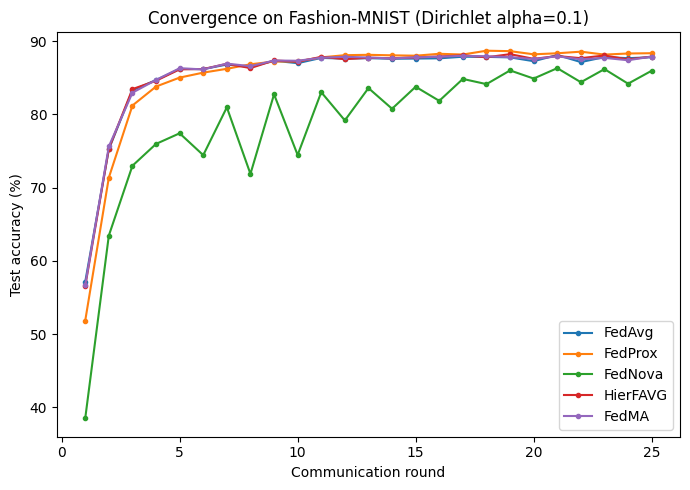

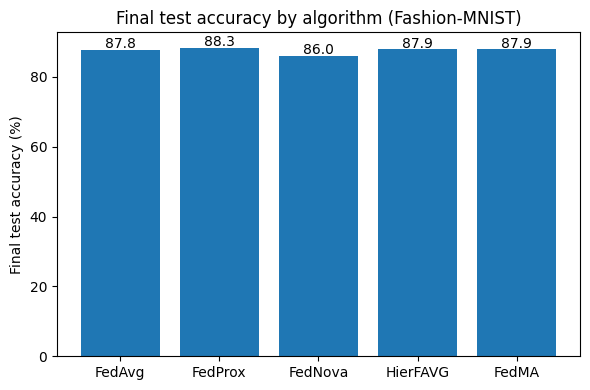

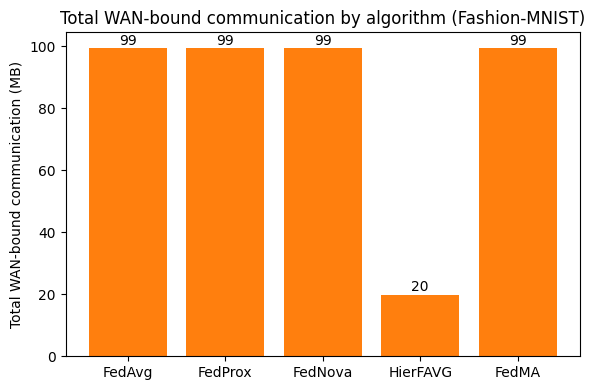

,Model,Accuracy (%),Communication (MB),Convergence round,Latency (s/round)
0,FedAvg,87.8,99.4,21,0.09
1,FedProx,88.3,99.4,18,0.09
2,FedNova,86.0,99.4,21,0.09
3,HierFAVG,87.9,19.9,19,0.09
4,FedMA,87.9,99.4,17,0.09


In [9]:
fig, ax = fc.plot_convergence(histories, title=f"Convergence on Fashion-MNIST (Dirichlet alpha={ALPHA})")
plt.show()

fig, ax = fc.plot_final_accuracy_bar(histories, title=f"Final test accuracy by algorithm (Fashion-MNIST)")
plt.show()

fig, ax = fc.plot_communication_bar(histories, title=f"Total WAN-bound communication by algorithm (Fashion-MNIST)")
plt.show()

results_df = pd.DataFrame(fc.summary_table(histories))
results_df


## Effect of distributional skew (paper Sec III-F, optional/slower)

In [10]:
# ---------------------------------------------------------------------------
# Optional: effect of distributional skew (paper Sec III-F).
# Re-runs FedAvg and FedNova at a few Dirichlet alpha values to see the
# accuracy gap narrow as alpha grows (clients become closer to IID).
# This repeats client partitioning + training, so it takes roughly as long
# as the main sweep above per alpha value -- shrink ALPHAS or NUM_ROUNDS_SKEW
# if you just want a quick look.
# ---------------------------------------------------------------------------
ALPHAS = [0.1, 0.5, 1.0]
NUM_ROUNDS_SKEW = 10
skew_results = []

for a in ALPHAS:
    idx_a = fc.dirichlet_partition(train_labels, num_clients=NUM_CLIENTS, alpha=a, num_classes=10, seed=SEED)
    sizes_a = [len(i) for i in idx_a]
    loaders_a = [DataLoader(Subset(train_dataset, i), batch_size=BATCH_SIZE, shuffle=True) for i in idx_a]
    for algo in ["FedAvg", "FedNova"]:
        fc.set_seed(SEED)
        h = fc.run_federated_experiment(
            algorithm=algo, model_fn=model_fn, client_loaders=loaders_a, client_sizes=sizes_a,
            test_loader=test_loader, device=device, rounds=NUM_ROUNDS_SKEW,
            local_epochs=LOCAL_EPOCHS, lr=LR, mu=MU_FEDPROX,
            cluster_of=cluster_of, num_clusters=NUM_CLUSTERS,
            fedma_match_layer=None, speed_multipliers=speed_multipliers,
            eval_every=NUM_ROUNDS_SKEW, verbose=False,
        )
        skew_results.append({"alpha": a, "algorithm": algo, "final_accuracy": h["accuracy"][-1]})
        print(f"alpha={a}  {algo}: {h['accuracy'][-1]:.1f}%")

skew_df = pd.DataFrame(skew_results).pivot(index="alpha", columns="algorithm", values="final_accuracy")
skew_df


alpha=0.1  FedAvg: 87.6%
alpha=0.1  FedNova: 76.2%
alpha=0.5  FedAvg: 89.2%
alpha=0.5  FedNova: 89.0%
alpha=1.0  FedAvg: 89.1%
alpha=1.0  FedNova: 89.2%


algorithm,FedAvg,FedNova
alpha,,
0.1,87.63,76.15
0.5,89.20,89.03
1.0,89.14,89.25


## Reading the results

- **FedAvg** is the baseline: expect it to be both the least accurate and the
  slowest to converge under the high-skew (`alpha=0.1`) regime, since plain
  coordinate-wise averaging of very different client gradients is not
  representative of any one client (paper Sec I-D).
- **FedProx** and **FedNova** should generally beat FedAvg here -- the
  proximal penalty and step-count normalisation both correct a real
  source of bias rather than acting as noise (paper Sec II-B, Sec III-E).
  Note the paper's own reduced-scale MNIST/Fashion-MNIST reproduction found
  FedNova's advantage did *not* hold on Fashion-MNIST -- so don't be
  surprised if your run shows something similar; it's a genuine,
  dataset-dependent finding, not a bug.
- **HierFAVG** should land close to FedAvg's accuracy while using
  dramatically less WAN-bound communication (roughly `1 - NUM_CLUSTERS/NUM_CLIENTS`
  less, mechanically, since only the cluster models cross the WAN).
- **FedMA-lite** channel-matches the first conv layer before averaging; on a
  network this small the benefit over FedAvg may be modest since there's
  only one conv layer's worth of permutation ambiguity to resolve -- the
  paper's full FedMA (matching *every* layer on a much larger ResNet-18)
  is where the effect is largest.

Because this notebook defaults to a small model, few clients, and few
rounds (for tractability without a GPU), don't expect the *absolute*
accuracy numbers to match the paper's Table VI/VII/VIII -- the paper itself
makes the same caveat about its own reduced-scale MNIST/Fashion-MNIST
companion runs. What should transfer is the *qualitative ranking* between
algorithms. Scale `NUM_CLIENTS`, `NUM_ROUNDS`, and the model size up (and
swap in `fc.set_seed` per run if you want multiple repeats) to move closer
to the paper's absolute numbers.


**Fashion-MNIST specific note (paper Sec III-E):** watch for FedNova being *less* stable here than on MNIST -- the paper attributes this to the larger spread of local-epoch counts (from the 0.25x-4x compute-heterogeneity model) interacting badly with FedNova's step-count rescaling on Fashion-MNIST's more visually ambiguous classes.